# 01 · Stage 1: LTspice simulation of smooth $R_F$ ramps

**Purpose.** Runs the LTspice simulations of Stage 1: the feedback resistor $R_F$ of a Wien-bridge oscillator is ramped linearly through its threshold, up from the quiet state or down from full oscillation, at many ramp rates. For each run the notebook saves the output time series and the resistance at which the oscillation switched on or off.

**In the report.** Chapter 4 (Sec. 4.1, Fig. 4.1); the switching points feed notebook 02 (Eqs. 4.1–4.3, Fig. 4.2).

## Theory

The Stage 1 circuit is the Wien bridge with $R = 1\,\mathrm{k\Omega}$, $C = 2\,\mu\mathrm{F}$ ($\omega_0 = 500\,\mathrm{s^{-1}}$), $R_i = 47\,\mathrm{k\Omega}$ and an LM741 on $\pm 15$ V. The ideal threshold $G = 1 + R_F/R_i = 3$ lies at $R_F = 94\,\mathrm{k\Omega}$. The feedback resistor is a behavioural resistor

$$R_F(t) = R_0 + \lambda t ,$$

with $R_0 = 93.5\,\mathrm{k\Omega}$, $\lambda > 0$ for ramps up (from the quiet state) and $R_0 = 100\,\mathrm{k\Omega}$, $\lambda < 0$ for ramps down (from full oscillation). A noise-free circuit would never start oscillating, so a small random voltage, `0.001*white(5e2*time)` (about 1 mV peak to peak, changing every 2 ms), is placed in series with $R_i$.

Theory (notebook 00, Eqs. 2.22 and 2.24) predicts that the switching points lag behind the threshold by an amount proportional to $\sqrt{\lambda}$.

## Method

1. For each rate, set the schematic parameters `R0`, `lam` and `Tstop` and run LTspice through `PyLTSpice`.
2. Read the output voltage $V_{\rm out}(t)$ from the `.raw` file and save it as a two-column CSV (`time`, `V(vout)`).
3. Switching point:
   - **ramp up:** the first time $|V_{\rm out}|$ exceeds `ON_LEVEL` = 13 V (the rail is about 13.9 V, so this is about 94 % of full size); $R_{\rm on} = R_0 + \lambda t$ at that moment;
   - **ramp down:** the last time $|V_{\rm out}|$ exceeds `OFF_LEVEL` = 1.4 V (about 10 % of full size); $R_{\rm off} = R_0 + \lambda t$ just after it.
4. Append one row per run (`Lambda, R0, Schematic, R_threshold_reached`) to the summary CSV used by notebook 02.

The run times are chosen to end shortly after the switch: up-ramps stop 20 s after the static crossing time; down-ramps stop when $R_F$ reaches `R_END` = 88 kΩ.

## Requirements

- LTspice (version 24 or later, Windows or macOS), only for the simulation cells.
- The LM741 model `lm741.lib` from Texas Instruments (the LM741 product page, "PSpice model", archive `snom211b`). Put it next to the schematic or set `LM741_LIB`.
- Python: `numpy`, `pandas`, `matplotlib`, and `PyLTSpice` (which installs `spicelib`) for the simulation cells.

Without LTspice, set `RUN_SIMULATION = False` (the default): the analysis cells below still run on the included sample time series.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
RUN_SIMULATION = False              # True -> run LTspice (needs LTspice + PyLTSpice); False -> analyse saved files only
LTSPICE_EXE    = r"C:\Program Files\LTspice.exe"          # path to the LTspice executable
SCHEMATIC      = "../ltspice/stage1_ramp/wien_bridge_ramp.asc"   # Stage 1 schematic (R = 1 k, C = 2 uF)
DIRECTION      = "up"               # "up": R_F rises from R0_UP; "down": R_F falls from R0_DOWN
RATES          = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 150, 200, 250, 300, 350, 400, 450, 500,
                  600, 700, 800, 900, 1000, 1500, 2000, 2500, 3000, 3500, 4000, 4500, 5000,
                  6000, 7000, 8000, 9000, 10000]                # ohm/s, magnitudes (report: 36 up, 28 down)
R0_UP, R0_DOWN = 93.5e3, 100e3      # ohm, starting R_F for the two directions (report values)
R_CRIT         = 94e3               # ohm, ideal threshold R_F = 2 R_i (used only for the up-ramp run length)
R_END          = 88e3               # ohm, down-ramps stop here
ON_LEVEL       = 13.0               # V, switch-on level (first |Vout| above it)
OFF_LEVEL      = 1.4                # V, switch-off level (last |Vout| above it)

TS_FOLDER      = "../data/stage1"                          # where time series are written / read
SUMMARY_CSV    = "outputs/01_stage1/simulation_summary.csv" # summary written by this notebook
SAMPLE_FILES   = {"up": "../data/stage1/time_series_lambda_1000.csv",       # used when RUN_SIMULATION = False
                  "down": "../data/stage1/time_series_lambda_-1000.csv"}
OUT_DIR        = "outputs/01_stage1"

## 1. Helper functions

In [2]:
import os, csv, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d
os.makedirs(OUT_DIR, exist_ok=True)

def switching_point(t, v, lam, R0):
    # Resistance at which the oscillation switched on (lam > 0) or off (lam < 0); NaN if it never did.
    if lam > 0:
        idx = np.where(np.abs(v) > ON_LEVEL)[0]
        return R0 + lam * t[idx[0]] if len(idx) else np.nan
    idx = np.where(np.abs(v) > OFF_LEVEL)[0]
    if len(idx) == 0:
        return np.nan
    j = min(idx[-1] + 1, len(t) - 1)          # first sample after the last one above the level
    return R0 + lam * t[j]

def envelope(v, dt, window=0.016):
    # Running maximum of |v| over about one oscillation period.
    n = max(3, int(round(window / dt))) | 1
    return maximum_filter1d(np.abs(v), n, mode="nearest")

## 2. Run the simulations (needs LTspice)

Each run edits the schematic's `.param` line, runs LTspice, reads `V(vout)`, saves the time series and records the switching point. LTspice's own files are deleted after each run.

In [3]:
def run_ramp(lam, R0, t_stop, editor_cls, runner_cls, raw_cls):
    runner = runner_cls(output_folder=OUT_DIR)
    editor = editor_cls(SCHEMATIC)
    editor.set_parameters(R0=str(R0), lam=str(lam), Tstop=str(t_stop))
    runner.run(editor); runner.wait_completion()
    raw_file, log_file = list(runner)[0]
    raw = raw_cls(raw_file)
    t = raw.get_trace("time").get_time_axis(); v = raw.get_trace("V(vout)").get_wave()
    for f in (raw_file, log_file, str(raw_file).replace(".raw", ".net")):
        if os.path.exists(f): os.remove(f)
    return np.abs(np.asarray(t, float)), np.asarray(v, float)

if RUN_SIMULATION:
    from PyLTSpice import SimRunner, RawRead, SpiceEditor
    from spicelib.simulators.ltspice_simulator import LTspice
    LTspice.create_from(LTSPICE_EXE)
    rows = []
    for mag in RATES:
        lam = mag if DIRECTION == "up" else -mag
        R0 = R0_UP if lam > 0 else R0_DOWN
        t_stop = (R_CRIT - R0) / lam + 20.0 if lam > 0 else (R_END - R0) / lam
        print(f"lambda = {lam} ohm/s, Tstop = {t_stop:.2f} s")
        t, v = run_ramp(lam, R0, t_stop, SpiceEditor, SimRunner, RawRead)
        np.savetxt(os.path.join(TS_FOLDER, f"time_series_lambda_{lam:g}.csv"), np.column_stack((t, v)),
                   delimiter=",", header="time,V(vout)", comments="")
        rows.append([lam, R0, os.path.basename(SCHEMATIC), switching_point(t, v, lam, R0)])
    new = pd.DataFrame(rows, columns=["Lambda", "R0", "Schematic", "R_threshold_reached"])
    if os.path.exists(SUMMARY_CSV):
        old = pd.read_csv(SUMMARY_CSV); new = pd.concat([old[~old.Lambda.isin(new.Lambda)], new])
    new.sort_values("Lambda").to_csv(SUMMARY_CSV, index=False)
    print(new.to_string(index=False))
else:
    print("RUN_SIMULATION = False: no LTspice runs. The cells below analyse the included sample files.")

RUN_SIMULATION = False: no LTspice runs. The cells below analyse the included sample files.


## 3. Switching points from saved time series (no LTspice needed)

Reads time series (the samples, or all files in `TS_FOLDER` after a simulation batch), recomputes each switching point with the same rule and plots the envelope against the instantaneous $R_F$, as in Fig. 4.1.

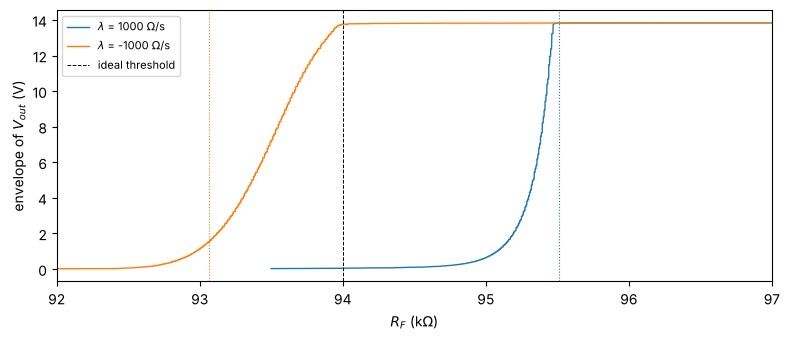

                        file  Lambda       R0  R_threshold_reached
 time_series_lambda_1000.csv  1000.0  93500.0         95509.849648
time_series_lambda_-1000.csv -1000.0 100000.0         93062.568726


In [4]:
import glob, re
files = sorted(glob.glob(os.path.join(TS_FOLDER, "time_series_lambda_*.csv"))) if RUN_SIMULATION else list(SAMPLE_FILES.values())
rows = []
fig, ax = plt.subplots(figsize=(8, 3.5))
for f in files:
    lam = float(re.findall(r"time_series_lambda_(-?[\d.]+)\.csv", f)[0])
    R0 = R0_UP if lam > 0 else R0_DOWN
    d = pd.read_csv(f); t = d.iloc[:, 0].to_numpy(float); v = d.iloc[:, 1].to_numpy(float)
    Rsw = switching_point(t, v, lam, R0)
    rows.append(dict(file=os.path.basename(f), Lambda=lam, R0=R0, R_threshold_reached=Rsw))
    R = R0 + lam * t
    ax.plot(R / 1e3, envelope(v, np.median(np.diff(t))), lw=1, label=f"$\\lambda$ = {lam:g} $\\Omega$/s")
    ax.axvline(Rsw / 1e3, color=ax.lines[-1].get_color(), ls=":", lw=0.8)
ax.axvline(R_CRIT / 1e3, color="k", ls="--", lw=0.7, label="ideal threshold")
ax.set_xlabel(r"$R_F$ (k$\Omega$)"); ax.set_ylabel(r"envelope of $V_{out}$ (V)"); ax.set_xlim(92, 97); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "envelope_vs_RF.png"), dpi=150); plt.show()
res = pd.DataFrame(rows); print(res.to_string(index=False))
res.to_csv(os.path.join(OUT_DIR, "switching_points_from_files.csv"), index=False)

## Check against the report

In [5]:
ref = pd.read_csv("../data/stage1/simulation_summary_master.csv")    # the full Stage 1 summary used in the report
for _, r in res.iterrows():
    m = ref[np.isclose(ref.Lambda, r.Lambda)]
    if len(m):
        diff = r.R_threshold_reached - m.R_threshold_reached.iloc[0]
        print(f"lambda = {r.Lambda:+g}: recomputed {r.R_threshold_reached:.1f} ohm, report summary "
              f"{m.R_threshold_reached.iloc[0]:.1f} ohm -> {'PASS' if abs(diff) < 5 else 'FAIL'} (difference {diff:+.1f} ohm)")

lambda = +1000: recomputed 95509.8 ohm, report summary 95509.5 ohm -> PASS (difference +0.4 ohm)
lambda = -1000: recomputed 93062.6 ohm, report summary 93062.6 ohm -> PASS (difference +0.0 ohm)


## Using your own circuit or data

- **Different circuit:** edit the schematic (component values, model) and keep the parameters `R0`, `lam`, `Tstop` and the node name `vout`.
- **Your own time series:** a CSV with time (s) in the first column and output voltage (V) in the second, one header line. Name it `time_series_lambda_<rate>.csv` with a negative rate for down-ramps, put it in `TS_FOLDER`, and set `RUN_SIMULATION = True` only if you also want new simulations; otherwise add the file to `SAMPLE_FILES`.
- The switching rule assumes the ramp is linear and starts at $t = 0$ with $R_F = R_0$, and that the rail is near 14 V; scale `ON_LEVEL` and `OFF_LEVEL` to about 94 % and 10 % of your rail.